In [1]:
import pandas as pd
import config.config as config

2025-05-30 17:05:19,949 - config.config - WARNING - No data available for Q3_2007
2025-05-30 17:05:20,194 - config.config - INFO - {'clustering_method': 'KMeans', 'n_clusters': 10, 'seed': 42, 'n_init': 10, 'num_stocks': 10, 'parallel': False, 'threshold': 0.25}


In [2]:
# Import Strategy Data

df_dict = config.df_dict

# Import Market Data

market_data = config.market_prices

In [3]:
# Process Raw Strategy Data

import data.process as processing

processed_df_dict = processing.process_data(df_dict)

In [4]:
import logging
logging.getLogger().setLevel(logging.WARNING)

In [5]:
# Feature Engineer

import features.pipeline as pipeline

engineered_data = pipeline.process_data(processed_df_dict)

2025-05-30 17:05:29,726 - features.pipeline - WARNING - No data generated for cluster 4


In [6]:
from typing import Dict

def shift_quarters(quarterly_data: Dict[str, pd.DataFrame], shift: int = 2) -> Dict[str, pd.DataFrame]:
    keys = list(quarterly_data.keys())
    shifted_eval_data = {
        keys[i]: quarterly_data[keys[i - shift]] if i - shift >= 0 else quarterly_data[keys[0]]
        for i in range(len(keys))
    }
    return shifted_eval_data


eval_data = shift_quarters(engineered_data, shift=2)

In [7]:
import models.pipeline as model

strategies = model.process_models(engineered_data)

In [8]:
signal = model.make_predict(strategies, eval_data)

/Users/parkercarrus/Desktop/Clustering-Paper.nosync/models/utils.py:42: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(0)


In [9]:
from config.config import constituent_dict

for quarter in signal.iterrows():
    quarter_consts = constituent_dict[quarter[0]]
    for equity in quarter[1].index:
        if quarter[1][equity] == 1:
            if equity not in quarter_consts:
                print(equity)


# this prints nothing, which ensures that we are NOT buying any equities that are NOT current constituents

In [10]:
# check if we are buying equities that leave the universe

constituent_list = list(constituent_dict.values())

leavers = set()
rejoiners = set()
for i in range(len(constituent_list)):
    for equity in constituent_list[i]:
        if equity in leavers:
            rejoiners.add(equity)
        for k in range(i+1, len(constituent_list)-1):
            if equity not in constituent_list[k]:
                leavers.add(equity)

In [11]:
count=0
for quarter in signal.iterrows():
    for equity in quarter[1].index:
        if quarter[1][equity] == 1:
            if equity in leavers:
                count+=1

count

# We bought 181 stocks that ended up leaving the sp500, confirming that we are buying according to the current trading universe

196

In [12]:
from backtest import matrix

prices = config.market_prices

In [13]:
cols = []
for col in prices:
    if col not in signal.columns:
        cols.append(col)

prices = prices.drop(columns=cols)

In [14]:
cols2 = []
for col in signal.columns:
    if col not in prices.columns:
        cols2.append(col)

In [ ]:
import wrds

# Connect to WRDS
db = wrds.Connection()

# Get delisted stock data for tickers in cols2
# We'll use CRSP's delist table (dlret) and stock names (msenames) for mapping
cols2_list = list(cols2)  # cols2 is already defined in a previous cell

# Get PERMNOs for the tickers in cols2
msenames = db.get_table(library='crsp', table='msenames')
cols2_msenames = msenames[msenames['ticker'].isin(cols2_list)]

# Get delisting info for these PERMNOs
delist = db.get_table(library='crsp', table='dse')
delisted_data = delist[delist['permno'].isin(cols2_msenames['permno'])]

# Merge to get ticker info with delisting data
delisted_data = delisted_data.merge(cols2_msenames[['permno', 'ticker']], on='permno', how='left')

delisted_data.head()

In [ ]:
cols2_msenames['permno']

862       10233
863       10233
2429      10696
2430      10696
2431      10696
          ...  
103773    89179
106775    89986
106776    89986
108801    90546
108802    90546
Name: permno, Length: 204, dtype: Int64

In [ ]:
relevant_stocks = delisted_data[delisted_data['permno'].isin(cols2_msenames['permno'])]
relevant_data = relevant_stocks[pd.to_datetime(relevant_stocks['date'], errors='coerce') > pd.Timestamp('2007-01-01')]

In [ ]:
by_permno = relevant_data.groupby(by='permno')
tickers = set()
for permno in by_permno:
    tickers.add(permno[1]['ticker_y'].iloc[0])

In [ ]:
price_dfs = {ticker: prices[[ticker]].dropna() for ticker in tickers if ticker in prices.columns}

In [ ]:
# Step 1: Extract relevant PERMNOs from delisted_data
delisted_permnos = delisted_data['permno'].unique().tolist()

# Step 2: Pull daily price data from crsp.dsf (this includes closing price as 'prc')
price_data = db.raw_sql(f"""
    SELECT permno, date, prc, vol, ret, shrout
    FROM crsp.dsf
    WHERE permno IN ({','.join(map(str, delisted_permnos))})
    ORDER BY permno, date
""", date_cols=['date'])

# Step 3: Optionally merge back with ticker names if needed
price_data = price_data.merge(cols2_msenames[['permno', 'ticker']], on='permno', how='left')

# Result: daily historical price data for all delisted stocks in cols2
price_data.head()


,permno,date,prc,vol,ret,shrout,ticker
0,10233,1925-12-31,108.0,5100.0,<NA>,370.0,ABC
1,10233,1925-12-31,108.0,5100.0,<NA>,370.0,ABC
2,10233,1926-01-02,108.5,1200.0,0.00463,370.0,ABC
3,10233,1926-01-02,108.5,1200.0,0.00463,370.0,ABC
4,10233,1926-01-04,108.0,1300.0,-0.004608,370.0,ABC


In [ ]:
price_data_filtered = price_data[price_data['date'] > pd.Timestamp('2000-01-01')]

In [ ]:
# Remove duplicate (date, ticker) pairs before pivoting
price_data_nodup = price_data_filtered.drop_duplicates(subset=['date', 'ticker'], keep='last')

# Pivot to have 'date' as index and each ticker as a column, values as 'prc'
price_pivot = price_data_nodup.pivot(index='date', columns='ticker', values='prc').reset_index()
price_pivot

ticker,date,AA,ABC,ADS,ANTM,ARNC,BLL,CBS,CDAY,COG,...,HFC,JEC,NLOK,PEAK,PKI,RE,SYMC,UTX,VIAC,WLTW
0,2000-01-03,80.9375,15.5625,<NA>,<NA>,80.9375,39.8125,17.375,<NA>,14.8125,...,13.625,31.9375,56.875,10.375,41.4375,21.875,56.875,62.5,56.9375,<NA>
1,2000-01-04,81.3125,14.5,<NA>,<NA>,81.3125,38.5,17.1875,<NA>,14.375,...,13.75,31.75,54.25,9.5,39.5,21.8125,54.25,59.9375,53.6875,<NA>
2,2000-01-05,86.0,15.625,<NA>,<NA>,86.0,39.1875,17.25,<NA>,14.625,...,13.9375,31.9375,51.0,9.875,39.0625,23.25,51.0,58.75,51.3125,<NA>
3,2000-01-06,84.875,16.8125,<NA>,<NA>,84.875,39.8125,16.875,<NA>,14.9375,...,13.75,32.07813,48.0625,10.625,39.5625,24.3125,48.0625,61.5625,51.125,<NA>
4,2000-01-07,84.625,19.0,<NA>,<NA>,84.625,38.6875,17.0,<NA>,15.5625,...,13.8125,32.8125,51.875,10.875,40.0625,25.625,51.875,64.0,54.125,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6284,2024-12-24,112.04,227.53999,62.95,372.94,112.04,56.16,10.42,74.23,24.73,...,34.4,136.0,27.85,20.39,112.34,362.38,27.85,116.83,10.42,316.03
6285,2024-12-26,112.53,226.59,63.32,373.66,112.53,56.19,10.44,74.15,24.58,...,34.34,136.24001,27.86,20.26,112.5,362.13,27.86,117.04,10.44,317.87
6286,2024-12-27,111.23,226.92999,61.93,371.07001,111.23,55.83,10.4,73.72,24.64,...,34.23,135.07001,27.65,20.08,111.99,359.95001,27.65,116.71,10.4,316.31
6287,2024-12-30,110.28,224.71001,61.4,368.79999,110.28,54.99,10.34,72.49,25.52,...,34.22,133.5,27.38,19.98,111.31,359.67999,27.38,115.22,10.34,313.23999


In [ ]:
prices = config.market_prices
# Ensure 'date' column in price_pivot is datetime for merge
price_pivot['date'] = pd.to_datetime(price_pivot['date'], errors='coerce')
prices_reset = prices.reset_index()
prices_reset['date'] = pd.to_datetime(prices_reset['date'], errors='coerce')
merged_prices = prices_reset.merge(price_pivot, on='date', how='left', suffixes=('', '_delisted')).set_index('date')

In [ ]:
merged_prices

,index,Unnamed: 0,JAVA,ORCL,MSFT,AYE,TROW,HON,EMC,BEAM,...,HFC,JEC,NLOK,PEAK,PKI,RE,SYMC,UTX,VIAC,WLTW
date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,0,0,76.500,118.12500,116.56250,25.9375,35.1250,56.68750,114.000,32.2500,...,13.625,31.9375,56.875,10.375,41.4375,21.875,56.875,62.5,56.9375,<NA>
2000-01-04,1,1,71.750,107.68750,112.62500,26.2500,34.0625,55.68750,107.500,31.6875,...,13.75,31.75,54.25,9.5,39.5,21.8125,54.25,59.9375,53.6875,<NA>
2000-01-05,2,2,71.875,102.00000,113.81250,27.4375,34.0000,54.93750,103.000,31.8750,...,13.9375,31.9375,51.0,9.875,39.0625,23.25,51.0,58.75,51.3125,<NA>
2000-01-06,3,3,68.000,96.00000,110.00000,27.1875,35.0000,56.00000,99.625,32.1875,...,13.75,32.07813,48.0625,10.625,39.5625,24.3125,48.0625,61.5625,51.125,<NA>
2000-01-07,4,4,71.875,103.37500,111.43750,27.2500,34.7500,59.00000,107.375,32.2500,...,13.8125,32.8125,51.875,10.875,40.0625,25.625,51.875,64.0,54.125,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,6284,6284,NaN,171.41000,439.32999,NaN,117.0700,228.89999,NaN,NaN,...,34.4,136.0,27.85,20.39,112.34,362.38,27.85,116.83,10.42,316.03
2024-12-26,6285,6285,NaN,171.67999,438.10999,NaN,117.5800,231.86000,NaN,NaN,...,34.34,136.24001,27.86,20.26,112.5,362.13,27.86,117.04,10.44,317.87
2024-12-27,6286,6286,NaN,168.96001,430.53000,NaN,115.6700,229.50999,NaN,NaN,...,34.23,135.07001,27.65,20.08,111.99,359.95001,27.65,116.71,10.4,316.31


In [ ]:
merged_prices.to_csv('price_matrix.csv')

In [ ]:
for symbol in signal.columns:
    if symbol not in merged_prices.columns:
        print(symbol)

In [ ]:
signal.shape

(67, 727)

In [2]:
merged_prices.shape

NameError: name 'merged_prices' is not defined

In [ ]:
cumsum_signal = signal.cumsum()

In [ ]:
dropcols = [col for col in merged_prices.columns if col not in signal.columns]
truncated_prices = merged_prices.drop(columns=dropcols)

In [ ]:
truncated_prices.shape[1] == signal.shape[1]

True

In [ ]:
import numpy as np

# Calculate how many times each row should be repeated
n_signal = signal.shape[0]
n_prices = truncated_prices.shape[0]
repeats = np.full(n_signal, n_prices // n_signal)
repeats[:n_prices % n_signal] += 1  # Distribute the remainder

# Repeat each row accordingly
stretched_signal = pd.DataFrame(
    np.repeat(signal.values, repeats, axis=0),
    columns=signal.columns,
    index=truncated_prices.index  # Align index with prices
)

column_means = stretched_signal.mean(axis=0)

In [ ]:
stretched_cumsum = stretched_signal.cumsum()

product = stretched_cumsum * truncated_prices

In [ ]:
def scale_buy_signal(stretched_signal, price_data, purchase_amount):
    mask = stretched_signal == 1
    scaled_signal = stretched_signal.copy().astype(float)
    scaled_signal[mask] = purchase_amount / price_data[mask]

    return scaled_signal


In [ ]:
scaled_signal = scale_buy_signal(stretched_signal, truncated_prices, 100)

scaled_signal.shape

/var/folders/09/218_rqfd1nz9w6gzydgm_3_h0000gn/T/ipykernel_5183/3752379605.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[[0.33997415040544804]
 [0.3459489379367605]
 [0.3297935492381769]
 [0.33710894224956367]
 [0.3367343502710711]
 [0.3274608684262231]
 [0.33274548298006856]
 [0.32948929159802304]
 [0.34684887794387986]
 [0.3752486162801087]
 [0.3714296188600966]
 [0.36033440329829936]
 [0.3791756577114603]
 [0.3717610458292519]
 [0.35585920942816235]
 [0.35914380117799166]
 [1.7605633802816902]
 [1.6911889058007779]
 [1.699235344095157]
 [1.7455053237912377]
 [1.7491691446562883]
 [1.7674089784376106]
 [1.743071291615827]
 [1.694915254237288]
 [1.670285618840822]
 [1.622849724115547]
 [1.594896331738437]
 [1.6056518946692357]
 [1.677289500167729]
 [1.6975046681378374]
 [1.7349063150589867]
 [1.6605778811026237]
 [1.7241379310344827]
 [1.689189189189189]
 [1.676727028839705]
 [1.6165535079211122]

(6289, 727)

In [ ]:
scaled_signal = scaled_signal.fillna(0.0)

for row in scaled_signal.iterrows():
    for equity in row[1]:
        if equity != 0.0:
            print(row[1])

FTNT    0.0
CMI     0.0
ZTS     0.0
LKQ     0.0
XOM     0.0
       ... 
AOS     0.0
STE     0.0
AVGO    0.0
EL      0.0
CVC     0.0
Name: 2000-01-03 00:00:00, Length: 727, dtype: float64
FTNT    0.0
CMI     0.0
ZTS     0.0
LKQ     0.0
XOM     0.0
       ... 
AOS     0.0
STE     0.0
AVGO    0.0
EL      0.0
CVC     0.0
Name: 2000-01-03 00:00:00, Length: 727, dtype: float64
FTNT    0.0
CMI     0.0
ZTS     0.0
LKQ     0.0
XOM     0.0
       ... 
AOS     0.0
STE     0.0
AVGO    0.0
EL      0.0
CVC     0.0
Name: 2000-01-03 00:00:00, Length: 727, dtype: float64
FTNT    0.0
CMI     0.0
ZTS     0.0
LKQ     0.0
XOM     0.0
       ... 
AOS     0.0
STE     0.0
AVGO    0.0
EL      0.0
CVC     0.0
Name: 2000-01-03 00:00:00, Length: 727, dtype: float64
FTNT    0.0
CMI     0.0
ZTS     0.0
LKQ     0.0
XOM     0.0
       ... 
AOS     0.0
STE     0.0
AVGO    0.0
EL      0.0
CVC     0.0
Name: 2000-01-03 00:00:00, Length: 727, dtype: float64
FTNT    0.0
CMI     0.0
ZTS     0.0
LKQ     0.0
XOM     0.0
     

In [ ]:
for row in scaled_signal.iterrows():
    for equity in row[1].index:
        if row[1][equity] != 0.0:
            print(row[0], equity, row[1][equity])

2000-01-03 00:00:00 AAPL 0.8933556672250139
2000-01-03 00:00:00 NE 3.278688524590164
2000-01-03 00:00:00 COST 1.1235955056179776
2000-01-03 00:00:00 TE 5.460750853242321
2000-01-03 00:00:00 BXP 3.258655804480652
2000-01-03 00:00:00 SPG 4.419889502762431
2000-01-03 00:00:00 APA 2.93040293040293
2000-01-03 00:00:00 YUM 2.680067001675042
2000-01-04 00:00:00 AAPL 0.975609756097561
2000-01-04 00:00:00 NE 3.3126293995859215
2000-01-04 00:00:00 COST 1.188707280832095
2000-01-04 00:00:00 TE 5.498281786941581
2000-01-04 00:00:00 BXP 3.3126293995859215
2000-01-04 00:00:00 SPG 4.4692737430167595
2000-01-04 00:00:00 APA 3.0651340996168583
2000-01-04 00:00:00 YUM 2.735042735042735
2000-01-05 00:00:00 AAPL 0.9615384615384616
2000-01-05 00:00:00 NE 3.3542976939203353
2000-01-05 00:00:00 COST 1.168736303871439
2000-01-05 00:00:00 TE 5.2631578947368425
2000-01-05 00:00:00 BXP 3.2854209445585214
2000-01-05 00:00:00 SPG 4.43213296398892
2000-01-05 00:00:00 APA 2.97951582867784
2000-01-05 00:00:00 YUM 2.7

In [ ]:
scaled_cumsum = scaled_signal.cumsum()
ledger = scaled_signal * truncated_prices
ledger = ledger.fillna(0)
row_sum = ledger.sum(axis=1)

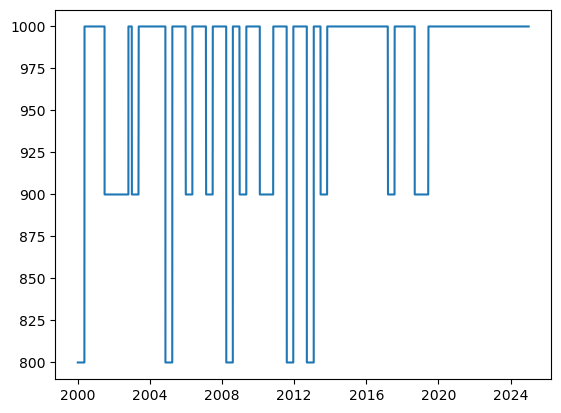

In [ ]:
import matplotlib.pyplot as plt

plt.plot(row_sum)

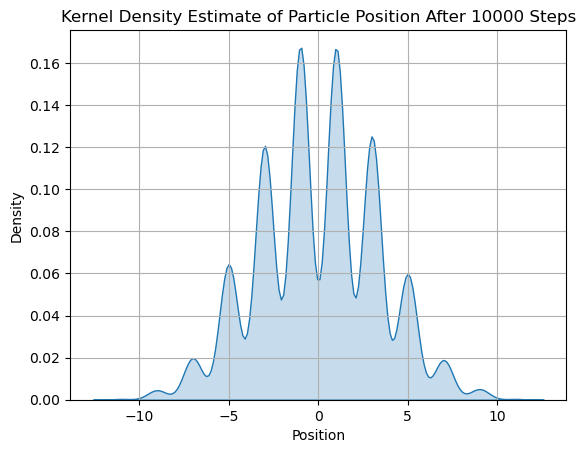

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Number of simulations
n_simulations = 10000

# Simulate the random walk
steps = 11
positions = []

for _ in range(n_simulations):
    # Randomly choose +1 or -1 for each step
    steps_taken = np.random.choice([-1, 1], size=steps)
    final_position = np.sum(steps_taken)
    positions.append(final_position)

# Plot the histogram
sns.kdeplot(positions, fill=True, bw_adjust=1)
plt.xlabel('Position')
plt.ylabel('Density')
plt.title('Kernel Density Estimate of Particle Position After 10000 Steps')
plt.grid(True)
plt.show()
